# Sample-Based Krylov Quantum Diagonalization (SKQD)

This tutorial adapted from:
* [ISC 2026 Tutorial (Part III)](https://isc-hpc.com/program/#contributed-program) by Alexander Orlov
* [CUDA Quantum SKQD Tutorial](https://nvidia.github.io/cuda-quantum/latest/applications/python/skqd.html) by NVIDIA.

Based on research by,
*   [University College London, Centre for Computational Science](https://www.ucl.ac.uk/mathematical-physical-sciences/computational-science),
*   [Technical University of Munich, Professorship for Quantum Computing](https://https://www.cs.cit.tum.de/en/qc/home/),
*   [Leibniz Supercomputing Centre, Quantum Computing and Technologies Department](https://www.lrz.de/en/technologies/quantum-computing),
*   [NVIDIA](https://www.nvidia.com/en-us/solutions/quantum-computing/),
*   [QMatter](https://qmatter.xyz/$0),
*   [IQM Quantum Computers](https://iqm.tech/),

Related Research and Publications:,
*   Orlov (2026): *Implementation of a Quantum Computing&ndash;High-Performance Computing Pipeline for Large-Scale Biomolecular Simulation* (M.Sc. Thesis),
*   QMatter (2026): [*A New Era of Biomolecular Simulation*](https://qmatter.xyz/a-new-era-of-biomolecular-simulation/) (Technical Blogpost),
*   NVIDIA (2026): [*Sample-Based Krylov Quantum Diagonalization (SKQD)*](https://nvidia.github.io/cuda-quantum/latest/applications/python/skqd.html) (CUDA-Q Tutorial),
*   Bickley et al. (2025): [*Extending quantum computing through subspace, embedding and classical molecular dynamics techniques*](https://doi.org/10.1039/D5DD00225G) (Digital Discovery),
*   Weaving et al. (2026): [*Selected Configuration Interaction Using Time-Evolved Population Statistics*](https://doi.org/10.1021/acs.jctc.5c01994) (J. Chem. Theory Comput.)

In [1]:
import time
import cudaq
import numpy as np
import pickle

from openfermion.chem import MolecularData, geometry_from_pubchem
from openfermion.transforms import get_fermion_operator
from openfermionpyscf import run_pyscf

from skqd_src.chemutils import water_geometry
from skqd_src.pre_and_postprocessing import *

from scipy.sparse import csr_matrix as sp_csr_matrix
from scipy.sparse.linalg import eigsh as sp_eigsh

# CuPy needs an NVIDIA GPU. Without one (e.g. the CPU Docker image) the
# post-processing falls back to NumPy/SciPy.
try:
    import cupy as cp
    HAS_GPU = cp.cuda.runtime.getDeviceCount() > 0
except Exception:
    cp, HAS_GPU = None, False

if HAS_GPU:
    from cupyx.scipy.sparse import csr_matrix as cp_csr_matrix
    from cupyx.scipy.sparse.linalg import eigsh as cp_eigsh

if cudaq.num_available_gpus() > 0 and cudaq.has_target("nvidia"):
    cudaq.set_target("nvidia")
else:
    cudaq.set_target("qpp-cpu")

cudaq.set_random_seed(42)
np.random.seed(43)
if HAS_GPU:
    cp.random.seed(44)

print("Using:", cudaq.__version__)
print("Simulator:", cudaq.get_target().name,
      "| Post-processing:", "GPU (CuPy)" if HAS_GPU else "CPU (NumPy/SciPy)")

if cudaq.get_target().name == "nvidia":
    shots = 100_000 
else:
    # Your CPU will thank you!
    shots = 1_000

/usr/local/lib/python3.12/site-packages/cudaq/__init__.py:260: UserWarning: cudaq-logical is in preview. Its APIs, behavior, and documentation may change substantially in upcoming versions.
  from . import logical  # noqa: F401
/tmp/ipykernel_5049/1662211363.py:2: FutureWarning: The CUDA-Q `sample` and `observe` algorithmic primitives will change in a future release. Existing code may require updates. See https://nvidia.github.io/cuda-quantum/latest/using/migration/upcoming_changes.html for details.
  import cudaq


Using: CUDA-Q Version 0.16.0 (https://github.com/NVIDIA/cuda-quantum 62fce8b862302158e0119c65e3ce57538f3af048)
Simulator: qpp-cpu | Post-processing: CPU (NumPy/SciPy)


## Using Quantum Computers for Science: A Biomolecular Use Case

Quantum computers can be integrated into biomolecular simulation workflows as specialized solvers for the hard chemistry parts of the simulation. 

Our workflow consists of the following steps:

1. Model the system and its reaction pathway
2. Generate Hamiltonians describing the region of interest of your molecule along the reaction pathway
3. Use this Hamiltonian and the QPU to sample from the system's wavefunction
4. Use these QPU samples to approximately diagonalize the Hamiltonian

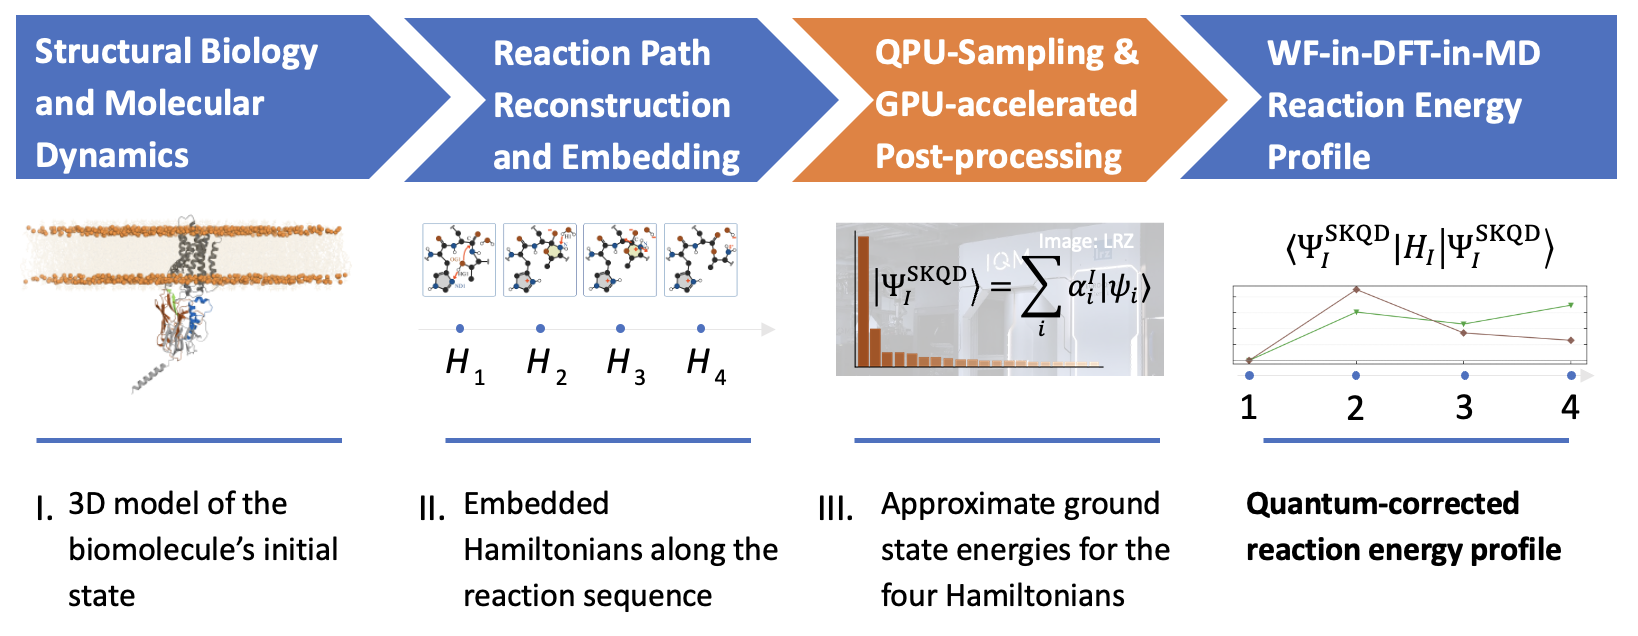

In practice, realistic Hamiltonians are often too large to be treated with both conventional and quantum computing resources. Therefore, multiscale methods such as the three-stage embedding pipeline below can be applied that describes only a small (but chemically important) part of the system with a Hamiltonian treated with a quantum computing algorithm, whereas the remainder is simulated with conventional resources.

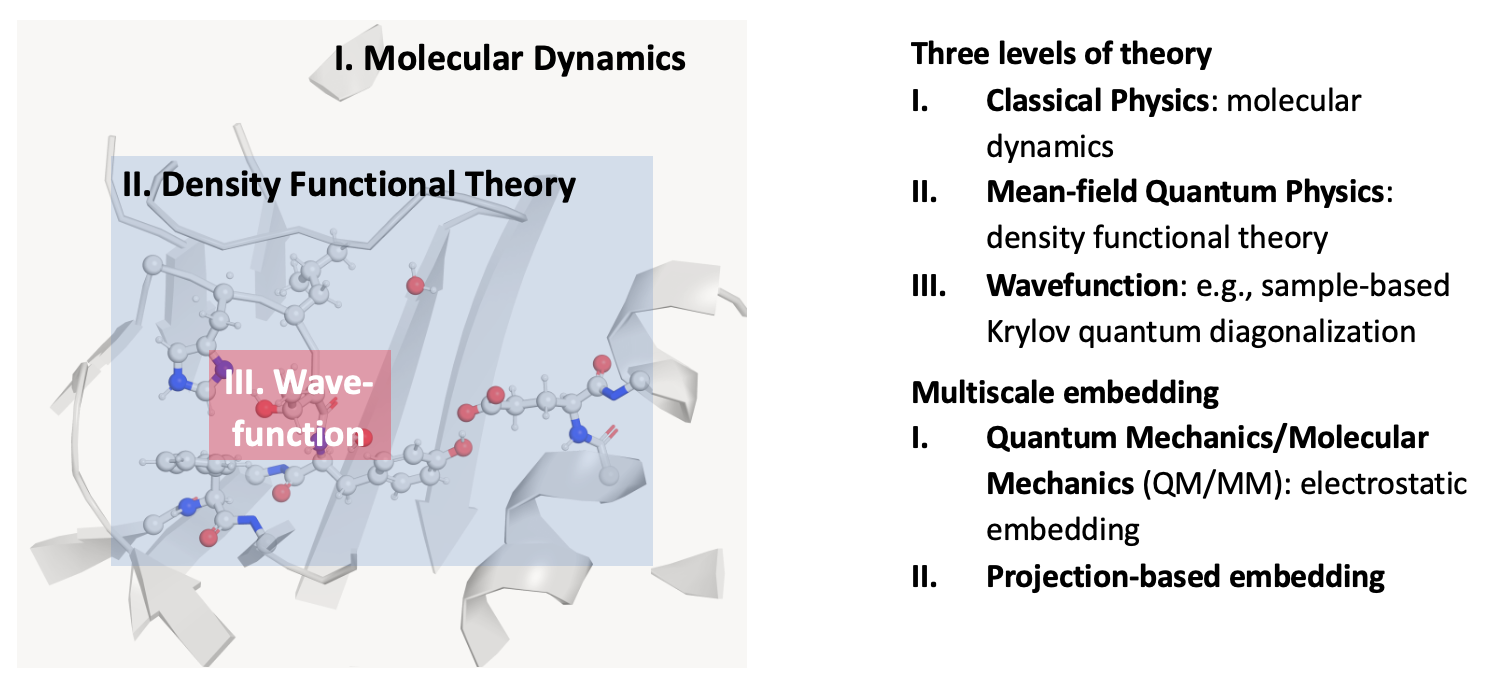

## Problem: Ground State of the Molecular Hamiltonian

The behaviour of molecules is governed by interactions of electrons and atomic nuclei.

We can describe the electronic structure of a molecule with the second-quantized Hamiltonian:

$$H = \underbrace{\sum_{pq} h_{pq}\, a_p^\dagger a_q}_{\text{Kinetic + Nuclear}} + \underbrace{\frac{1}{2}\sum_{pqrs} h_{pqrs}\, a_p^\dagger a_q^\dagger a_r a_s}_{\text{Electron-Electron Interactions}} $$

The two operators $a_p^\dagger$ and $a_q$ create and annihilate electrons in spin orbitals $p$ and $q$, respectively.

$$ a_p^\dagger |0_0, 0_1, \ldots, 0_p \ldots, 0_n \rangle = |0_0, 0_1, \ldots, 1_p, \ldots, 0_n \rangle $$

$$ a_p |0_0, 0_1, \ldots, 1_p \ldots, 0_n \rangle = |0_0, 0_1, \ldots, 0_p, \ldots, 0_n \rangle $$

Our problem is to find the lowest eigenvalue of the Hamiltonian, i.e. the energy $E_0$ of the ground state $|\psi_0\rangle$:

$$ H |\psi_0\rangle = E_0 |\psi_0\rangle $$

The real problem - *we do not know the ground state*!

### Toy Model: $H_2O$ in the $STO-3G$ Basis

Let's start by comparing two classical methods:

- Hartree-Fock: Cheap and approximate.
- Full Configuration Interaction (FCI): Expensive and exact.

In [2]:
from openfermion import MolecularData
from openfermionpyscf import run_pyscf

# Start with coordinates of a molecule's atoms.
geometry = water_geometry(bond_stretch=1.0)
print(f"{geometry=}")

# Run Hartree-Fock to get the Hamiltonian coefficients.
# - We also run Full Configuration Interaction (FCI) which acts as our ground truth for the energy.
molecule = run_pyscf(MolecularData(geometry, basis="sto-3g", multiplicity=1, charge=0),
                     run_scf=True, run_fci=True)

hartree_fock_energy = molecule.hf_energy
exact_ground_state_energy = molecule.fci_energy

if molecule.n_qubits >= 63:
    raise ValueError(f"Vectorized implementation of postprocessing supports max 62 qubits due to int64 packing. Requested: {molecule.n_qubits}")

print()
print(f"Hatree-Fock energy: {hartree_fock_energy:.6f} Hartree")
print(f"Exact ground state energy: {exact_ground_state_energy:.6f} Hartree")
print(f"Correlation energy: {hartree_fock_energy - exact_ground_state_energy:.6f} Hartree ({-100 * (hartree_fock_energy - exact_ground_state_energy) / exact_ground_state_energy:.2f}%)")


geometry=[('O', (0, 0, 0)), ('H', (0.2774, 0.8929, 0.2544)), ('H', (0.6068, -0.2383, -0.7169))]

Hatree-Fock energy: -74.964448 Hartree
Exact ground state energy: -75.015530 Hartree
Correlation energy: 0.051083 Hartree (0.07%)


### Question: How do the HF and FCI energy compare as we stretch the O-H bond in water?

Think about:
- The _equilibrium position_ of the energy minimum?
- The _reaction barrier_ (difference between the minimum energy and energy at infinite separation)?

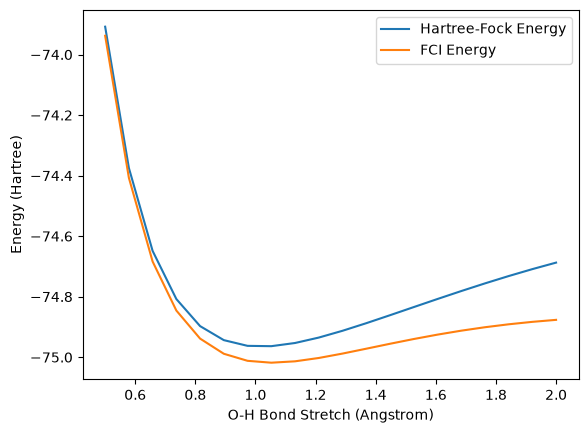

In [3]:
import matplotlib.pyplot as plt

bond_stretches = np.linspace(0.5, 2.0, 20)
hf_energies = []
fci_energies = []

for b in bond_stretches:
    g = water_geometry(bond_stretch=b)
    molecule = run_pyscf(MolecularData(g, basis="sto-3g", multiplicity=1, charge=0),
                         run_scf=True, run_fci=True)
    hf_energies.append(molecule.hf_energy)
    fci_energies.append(molecule.fci_energy)
    

plt.plot(bond_stretches, hf_energies, label="Hartree-Fock Energy") 
plt.plot(bond_stretches, fci_energies, label="FCI Energy") 
plt.ylabel("Energy (Hartree)")
plt.xlabel("O-H Bond Stretch (Angstrom)")
plt.legend()

## Method: Sample-Based Krylov Quantum Diagonalization (SKQD)

### What is a Krylov Subspace?

A **Krylov subspace** $\mathcal{K}^r$ of dimension $r$ is the space spanned by vectors obtained by repeatedly applying an operator $U$ to a reference vector $|\psi\rangle$:

$$ \mathcal{K}^r = \text{span}\{|\psi\rangle, U|\psi\rangle, U^2|\psi\rangle, \ldots, U^{r-1}|\psi\rangle\} $$

### The SKQD Algorithm

The key insight of SKQD is that we can:
1. **Generate** Krylov states $U^k|\psi\rangle$ using quantum time evolution
2. **Sample** from these states to get computational basis measurements
3. **Combine** all samples to form a computational subspace
4. **Diagonalize** the Hamiltonian within this subspace classically

This approach is much more efficient than computing matrix elements via quantum measurements!


### 1. Time evolution with qDRIFT
(Campbell, PRL 123, 070503, 2019)

We want our operator $U$ to approximate time evolution under the Hamiltonian $H$:
$$ U \approx e^{-i H t} $$

qDRIFT gives us a scalable way to do this, trading accuracy for efficiency.

For a Hamiltonian $H = \sum_j c_j h_j$ , we pick $N$ terms at random with probability $|c_j|/\lambda$ (with $\lambda = \sum_j |c_j|$).

Each term is added to the quantum circuit as $e^{-i\,\mathrm{sgn}(c_j)\,\lambda t/N\, h_j}$.

In [4]:
from skqd_src.chemutils import qdrift, jordan_wigner

total_time_evolution = np.pi
n_samples = 200  # gates in the qDRIFT sequence for one application of U
max_k = 12  # largest k for U^k

pauli_words, coefficients = jordan_wigner(molecule)

qdrift_terms, angles = qdrift(
    pauli_words,
    coefficients,
    samples=n_samples,
    total_time_evolution=total_time_evolution
    )


## Krylov State Generation via Repeated Evolution

For SKQD, we generate the Krylov sequence:
$$|\psi_0\rangle,  U|\psi_0\rangle,  U^2|\psi_0\rangle, \ldots,  U^{k-1}|\psi_0\rangle$$

where $U = e^{-iHT}$ is approximated by a qDRIFT sequence.

1. Start with the Hartree-Fock reference state $|\psi_0\rangle = |1\ldots1\,0\ldots0\rangle$ (the first 10 spin orbitals occupied)
2. Apply the qDRIFT time evolution $k$ times for $U^k|\psi_0\rangle$
3. Measure each Krylov state in computational basis
4. Accumulate measurement statistics across all Krylov powers

In [5]:
@cudaq.kernel
def quantum_krylov_evolution_circuit(
        num_qubits: int,
        num_occupied: int,
        krylov_power: int,
        U_pauli_words: list[cudaq.pauli_word],
        U_angles: list[float]):

    """
    Generate Krylov states via repeated time evolution.

    Args:
        num_qubits: Number of qubits in the system
        num_occupied: Number of occupied spin orbitals in the reference state
        krylov_power: Power k for computing U^k|ψ⟩
        U_pauli_words: Pauli words of the qDRIFT sequence for U
        U_angles: Rotation angle of each gate in the sequence

    Returns:
        Measurement results in computational basis
    """

    qubits = cudaq.qvector(num_qubits)

    #Prepare Hartree-Fock state as reference |11...100...0⟩
    for qubit_index in range(num_occupied):
        x(qubits[qubit_index])


    for _ in range(krylov_power):                              #applies U^k where U ≈ exp(-iHt)

        for i in range(len(U_angles)):                         #applies the qDRIFT sequence for U
            exp_pauli(U_angles[i], qubits, U_pauli_words[i])


    mz(qubits)

## Quantum Measurements and Sampling

For each Krylov power $k = 0, 1, 2, \ldots, K-1$:
1. **Prepare** the state $U^k|\psi_0\rangle$ using our quantum circuit
2. **Measure** in the computational basis many times
3. **Collect** the resulting bitstring counts


### QPU Circuit Simulator

Using cudaq we can build a quantum kernel and simulate the circuit.

In [6]:
sim_measurements = []

for krylov_power in range(max_k):
    t0 = time.perf_counter()

    sampling_result = cudaq.sample(
        quantum_krylov_evolution_circuit,
        molecule.n_qubits,
        molecule.n_electrons,
        krylov_power,
        qdrift_terms,
        angles,
        shots_count=shots)

    sim_measurements.append(dict(sampling_result.items()))
    print(f"Krylov state U^{krylov_power}: {len(sampling_result)} unique bitstrings "
          f"({time.perf_counter() - t0:.1f} s)")

cumulative_results = calculate_cumulative_results(sim_measurements)

Krylov state U^0: 1 unique bitstrings (0.1 s)
Krylov state U^1: 611 unique bitstrings (0.6 s)
Krylov state U^2: 631 unique bitstrings (1.1 s)
Krylov state U^3: 661 unique bitstrings (1.6 s)
Krylov state U^4: 660 unique bitstrings (2.1 s)
Krylov state U^5: 689 unique bitstrings (2.6 s)
Krylov state U^6: 672 unique bitstrings (3.2 s)
Krylov state U^7: 689 unique bitstrings (3.8 s)
Krylov state U^8: 668 unique bitstrings (4.0 s)
Krylov state U^9: 690 unique bitstrings (4.7 s)
Krylov state U^10: 644 unique bitstrings (5.2 s)
Krylov state U^11: 653 unique bitstrings (5.7 s)


## Real circuit - IQM QPU

Even for modest sizes of circuit, simulation isn't feasible. 

Luckily, IQM have given us their Emerald QPU to play with for today.

In [7]:
# TODO Find out how to connect up cudaq and IQM

qpu_measurements = []


## Classical Post-Processing and Diagonalization

Now comes the classical part of SKQD: we use our quantum measurement data to construct and diagonalize the Hamiltonian within each Krylov subspace.

1. **Extract basis states** from measurement counts
2. **Project Hamiltonian** onto the computational subspace spanned by these states  
3. **Diagonalize** the projected Hamiltonian classically
4. **Extract ground state energy** estimate



### Matrix Construction Details

The core of SKQD is constructing the effective Hamiltonian matrix within the computational subspace:

1. **Computational Subspace Formation**: From quantum measurements, we obtain a set of computational basis states $\{|s_1\rangle, |s_2\rangle, \ldots, |s_d\rangle\}$ that spans our approximation to the Krylov subspace.

2. **Matrix Element Computation**: For each Pauli term $P_k$ in the Hamiltonian with coefficient $h_k$:
   $$H = \sum_k h_k P_k$$
   
   We compute matrix elements $\langle s_i | P_k | s_j \rangle$ by applying the Pauli string $P_k$ to each basis state $|s_j\rangle$.

3. **Effective Hamiltonian**: The projected Hamiltonian becomes:
   $$H_{\text{eff}}[i,j] = \sum_k h_k \langle s_i | P_k | s_j \rangle$$

We demonstrate two eigenvalue solver approaches below: an explicit CSR sparse matrix and a matrix-free Lanczos iteration.


### Approach 1: Vectorized CSR Sparse Matrix

We build the projected Hamiltonian as a CuPy CSR sparse matrix on the GPU and solve with `cupyx.scipy.sparse.linalg.eigsh`. 

Without a GPU, the same vectorized code runs in NumPy and the matrix is solved with `scipy.sparse.linalg.eigsh`.


In [ ]:
csr_energies = []

for k in range(1, max_k):

    cumulative_subspace_results = cumulative_results[k]
    basis_states = get_basis_states_as_array(cumulative_subspace_results, molecule.n_qubits)
    
    subspace_dimension = len(cumulative_subspace_results)
    assert len(cumulative_subspace_results) == basis_states.shape[0]

    v0_np = np.random.random((subspace_dimension,)).astype(np.float64)
    v0_np = v0_np / np.linalg.norm(v0_np)

    matrix_rows, matrix_cols, matrix_elements = vectorized_projected_hamiltonian(
        basis_states, pauli_words, coefficients, HAS_GPU)

    if HAS_GPU:
        projected_hamiltonian = cp_csr_matrix(
            (matrix_elements, (matrix_rows, matrix_cols)),
            shape=(subspace_dimension, subspace_dimension))
        eigenvalue = cp_eigsh(projected_hamiltonian, return_eigenvectors=False,
                              k=1, which='SA', v0=cp.asarray(v0_np, dtype=cp.complex128))
    else:
        projected_hamiltonian = sp_csr_matrix(
            (matrix_elements, (matrix_rows, matrix_cols)),
            shape=(subspace_dimension, subspace_dimension))
        eigenvalue = sp_eigsh(projected_hamiltonian, return_eigenvectors=False,
                              k=1, which='SA', v0=v0_np)
    csr_energies.append(float(np.min(eigenvalue).real))
    print(f"k={k}: subspace dimension {subspace_dimension}, "
          f"E = {csr_energies[-1]:.6f} Ha, E - E_FCI = {csr_energies[-1] - exact_ground_state_energy:.1e} Ha")

k=1: subspace dimension 612, E = -74.691900 Ha, E - E_FCI = 3.2e-01 Ha
k=2: subspace dimension 1083, E = -74.862146 Ha, E - E_FCI = 1.5e-01 Ha
k=3: subspace dimension 1376, E = -74.865731 Ha, E - E_FCI = 1.5e-01 Ha
k=4: subspace dimension 1605, E = -74.867328 Ha, E - E_FCI = 1.5e-01 Ha


### Approach 2: Matrix-Free Lanczos via `distributed_eigsh`

Instead of explicitly constructing the projected Hamiltonian as a sparse matrix, we can apply the Hamiltonian as a linear operator during Lanczos iteration. This matrix-free approach avoids storing the full sparse matrix and naturally extends to multiple GPUs (demonstrated in the multi-GPU section below).

Without a GPU, `matrix_free_eigsh_cpu` applies the same bit-mask matrix-vector product with NumPy inside a SciPy `LinearOperator`.

In [ ]:
lo_energies = []

for k in range(1, max_k):

    cumulative_subspace_results = cumulative_results[k]
    basis_states = get_basis_states_as_array(cumulative_subspace_results, n_qubits)
    subspace_dimension = len(cumulative_subspace_results)

    v0_np = np.random.random((subspace_dimension,)).astype(np.float64)
    v0_np = v0_np / np.linalg.norm(v0_np)

    if HAS_GPU:
        v0 = cp.asarray(v0_np, dtype=cp.complex128)

        ham_data = prepare_hamiltonian_data(basis_states, pauli_words, hamiltonian_coefficients_numpy)
        cp.get_default_memory_pool().free_all_blocks()
        ncv = min(20, subspace_dimension - 1)

        eigenvalues, = distributed_eigsh(
            ham_data, rank=0, size=1, nccl_comm_obj=None,
            k=1, which='SA', ncv=ncv, v0_full=v0,
            tile_size=32, return_eigenvectors=False)

        eigenvalue_real = float(cp.asnumpy(eigenvalues[0]).real)
    else:
        eigenvalues = matrix_free_eigsh_cpu(
            basis_states, pauli_words, hamiltonian_coefficients_numpy,
            v0=v0_np, k=1, which='SA', return_eigenvectors=False)

        eigenvalue_real = float(eigenvalues[0].real)

    lo_energies.append(eigenvalue_real)

## Results Analysis and Convergence

Let's visualize our results and analyze how SKQD converges to the true ground state energy. 

### What to Expect:

- **Monotonic improvement**: Each additional Krylov dimension should give a better (lower) energy estimate
- **Convergence**: The estimates should approach the exact ground state energy  
- **Diminishing returns**: Later Krylov dimensions provide smaller improvements

The exact ground state energy for our selected Hamiltonian was computed earlier via classical exact diagonalization and will be used as the reference for comparison with SKQD results.


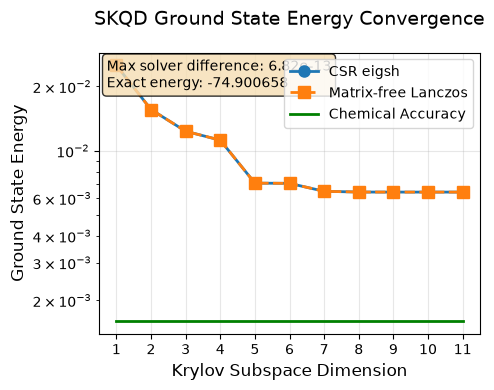

In [ ]:
plot_skqd_convergence(csr_energies, lo_energies, range(1, max_k), exact_ground_state_energy)

## Postprocessing Acceleration: CSR matrix approach, single GPU vs CPU 

The data in the plot below was gathered by averaging over 5 runs on a NVIDIA H100 GPU and an Intel Xeon Platinum 8480CL CPU with 224 threads. The only thing that changed between the 2 data points was `vectorized_pj_on_gpu = True` and `vectorized_pj_on_gpu = False`

This substantial acceleration comes from:
- **Parallel Pauli string evaluation** across thousands of basis states simultaneously
- **Vectorized matrix element computation** leveraging CUDA cores
- **GPU-optimized sparse linear algebra** via cuSPARSE library for eigenvalue solving

The speedup becomes increasingly critical as the Krylov dimension grows, since the computational subspace dimension (and thus the matrix size) scales exponentially with k. For higher k values, GPU acceleration transforms previously intractable postprocessing into feasible computation times.


<img src="images/speedup.png" width="500">


## Postprocessing Scale-Up and Scale-Out: Linear Operator Approach, Multi-GPU Multi-Node

The plots below were generated using `distributed_eigsh()` with the Hamiltonian of an active site of a GPCR (G protein-coupled receptor) molecule. This demonstrates scaling behavior on a problem with a much larger computational subspace than the 22-qubit demo above.

<div style="display: flex; gap: 10px;">
  <img src="images/strong_scaling_timing.jpeg" width="450">
  <img src="images/efficiency.jpeg" width="450">
</div>

### Saving Hamiltonian Data

To run the multi-GPU solver, we first save the Hamiltonian data (pauli words, coefficients) and the sampled basis states so they can be loaded by each MPI rank.

In [ ]:
# # uncomment this to save the data

# cumulative_subspace_results = cumulative_results[max_k-1]
# basis_states = get_basis_states_as_array(cumulative_subspace_results, num_spins)

# with open('skqd_data.pkl', 'wb') as f:
#     pickle.dump({
#         'basis_states': basis_states,
#         'pauli_words': pauli_words,
#         'hamiltonian_coefficients': hamiltonian_coefficients_numpy,
#     }, f)


### Running the Distributed Solver

Running the cell below saves the code as `distributed_postprocessing.py` (it needs GPUs and `mpi4py`, so it is not run in the notebook). Launch it with MPI. For example, on a system with 8 GPUs:

```bash
mpirun -np 8 --bind-to none --allow-run-as-root python distributed_postprocessing.py
```

In [ ]:
%%writefile distributed_postprocessing.py
"""
Multi-GPU SKQD Eigenvalue Solver

Usage:
    Save the code below in a distributed_postprocessing.py file
    Execute with the command below, for example on a system with 8 GPUs: 
    mpirun -np 8 --bind-to none --allow-run-as-root python distributed_postprocessing.py 
"""

import numpy as np
import cupy as cp
from skqd_src.pre_and_postprocessing import *
from mpi4py import MPI
import pickle
comm = MPI.COMM_WORLD
rank = comm.Get_rank()
size = comm.Get_size()

n_devices = cp.cuda.runtime.getDeviceCount()
my_gpu = rank % n_devices
cp.cuda.Device(my_gpu).use()

tile_size = 32

#uncomment this to load the data
# with open('skqd_data.pkl', 'rb') as f:
#     data = pickle.load(f)
#     basis_states = data['basis_states']
#     pauli_words = data['pauli_words']
#     hamiltonian_coefficients_numpy = data['hamiltonian_coefficients']



subspace_dimension = basis_states.shape[0]

ham_data = prepare_hamiltonian_data(basis_states, pauli_words, hamiltonian_coefficients_numpy)
cp.cuda.Device(my_gpu).synchronize()

nccl_comm_obj = None
if size > 1:
    from cupy.cuda import nccl
    if rank == 0:
        nccl_id = nccl.get_unique_id()
    else:
        nccl_id = None
    nccl_id = comm.bcast(nccl_id, root=0)
    nccl_comm_obj = nccl.NcclCommunicator(size, nccl_id, rank)

np.random.seed(42)
v0_np = np.random.random((subspace_dimension,)).astype(np.float64)
v0_np = v0_np / np.linalg.norm(v0_np)
v0 = cp.asarray(v0_np, dtype=cp.complex128)

cp.get_default_memory_pool().free_all_blocks()

ncv = min(20, subspace_dimension - 1)

eigenvalues, = distributed_eigsh(
    ham_data, rank, size, nccl_comm_obj,
    k=1, which='SA', ncv=ncv, v0_full=v0,
    tile_size=tile_size, return_eigenvectors=False)

eigenvalue = eigenvalues[0]
cp.cuda.Device(my_gpu).synchronize()
eigenvalue_real = float(cp.asnumpy(eigenvalue).real)

MPI.Finalize()


Overwriting distributed_postprocessing.py


## Summary

In this notebook we demonstrated the **Sample-Based Krylov Quantum Diagonalization (SKQD)** algorithm using CUDA-Q:

1. **Quantum phase**: Generated a sequence of Krylov states $U^k|\psi_0\rangle$ via qDRIFT time evolution on the 14-qubit Jordan-Wigner Hamiltonian of H$_2$O (STO-3G), and sampled each state in the computational basis.

2. **Classical post-processing**: Projected the Hamiltonian onto the computational subspace defined by the measurement outcomes, and extracted the ground state energy via eigenvalue solvers.

3. **Two solver approaches**: Compared an explicit GPU-accelerated CSR sparse matrix solver with a matrix-free Lanczos iteration (`distributed_eigsh`), showing both converge to the same result.

4. **GPU acceleration**: Demonstrated significant speedup of the classical post-processing when using GPU-vectorized operations compared to CPU.

5. **Multi-GPU scaling**: Showed how the matrix-free Lanczos solver scales across multiple GPUs using NCCL for distributed computation.


# Stretch Activity: Static vs Dynamic Correlation


The energy contribution from electron correlation can be classified into two types: **static correlation** and **dynamic correlation**. 

Static correlation is dominant near the equilibrium geometry of a molecule, but as we stretch bonds, dynamic correlation becomes more significant.

We can explore how well SKQD handles these by tuning the geometry of the water molecule and observing how the ground state energy estimates change with bond stretching.